# 02 · Data quality

**Goal:** decide if I can trust the data, and clean what I can explain. In `01_data_overview` I found a problem per building. Here I look at each one, fix it in `src/ahu_fdd/data.py` with a test, and check that the fix works.

**How to read this notebook.** Same pattern as notebook 01: a question in plain words, short code cells, then `Obs:`, `Decision:` and `Ask the operator:`.

The problems, in the order I look at them:

| # | Problem | Building |
|---|---|---|
| 1 | One week stamped 8 hours early | B1 office |
| 2 | One full day repeated | B3 mall |
| 3 | About 9 days missing | B2 hospital |
| 4 | Nulls, frozen sensors and impossible values | all |

Every decision also goes into `docs/decisions.md`.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

from ahu_fdd.config import (
    CLOCK_SHIFT_END,
    CLOCK_SHIFT_OFFSET,
    CLOCK_SHIFT_START,
    FROZEN_MIN_HOURS,
    FROZEN_SENSORS,
)
from ahu_fdd.data import (
    add_building,
    clean_sensors,
    fix_clock_shift,
    load_labels,
    load_metadata,
    load_sensors,
    merge_duplicates,
)
from ahu_fdd.eda import coverage_by_building, coverage_per_ahu, gap_blocks, longest_runs
from ahu_fdd.plots import BUILDING_COLORS, save_fig, set_style

set_style()  # same look for every chart

In [2]:
# Raw train diary, sorted by machine and time (load_sensors keeps the file order of duplicates)
train = add_building(load_sensors("train"))

## 1. Is one office week really stamped 8 hours early?

In notebook 01 the office (B1) looked like it ran at night from 2 to 8 June. My idea: that week was saved in UTC instead of Singapore time (UTC+8).

**How:** I need a clock I can trust. The three buildings are in the same city, so they see the same weather. If the office outside temperature (`oat_c`) matches the mall temperature 8 hours later, the office clock was 8 hours early. Like checking your watch against the church clock.

In [3]:
# Average outside temperature per timestamp in each building (all its machines see the same air)
oat = train.groupby(["building", "timestamp"])["oat_c"].mean()
office, mall = oat["B1"], oat["B3"]

# Gap between the office and the mall at the same stamp, and with the mall 8 hours later
check = pd.DataFrame({"office": office})
check["same_time"] = (office - mall.reindex(office.index)).abs()
check["mall_8h_later"] = (office - mall.reindex(office.index + pd.Timedelta("8h")).values).abs()

# One row per day around the suspicious week, with the day name
days = check.loc["2025-05-30":"2025-06-10"]
daily = days.groupby(days.index.date)[["same_time", "mall_8h_later"]].mean().round(1)
daily.index = [f"{d:%a %d %b}" for d in daily.index]
daily

,same_time,mall_8h_later
Fri 30 May,0.4,3.6
Sat 31 May,0.4,3.7
Sun 01 Jun,0.9,2.7
Mon 02 Jun,3.7,0.4
Tue 03 Jun,3.5,0.4
Wed 04 Jun,3.6,0.4
Thu 05 Jun,3.7,0.4
Fri 06 Jun,3.4,0.4
Sat 07 Jun,3.7,0.4
Sun 08 Jun,3.6,0.4


**How to read it:** each number is the average gap in °C between the office and the mall outside temperature on that day. A small gap means the two clocks agree.

First, one real example at a time. Singapore is hot in the afternoon (about 31 °C) and cooler at dawn (about 26 °C).

| Stamp in the office file | Office says | Mall at the same stamp | Mall 8 hours later | Which mall value is closer? |
|---|---|---|---|---|
| Fri 30 May 14:00 | 31.3 °C | 31.7 °C (gap 0.4) | 27.4 °C (gap 3.9) | same time: the office clock is right |
| Wed 4 Jun 06:00 | 30.6 °C | 25.5 °C (gap 5.1) | 31.0 °C (gap 0.4) | 8 hours later: the office clock is 8 hours early |

On 4 June the office says 30.6 °C "at 06:00", which is an afternoon temperature. It really is 14:00, and the mall at 14:00 says 31.0 °C. The table below does the same thing for every 5-minute row and averages the gaps per day.

- Fri 30 May: 0.4 °C at the same time and 3.6 °C with the mall 8 hours later. The clocks agree: normal day.
- Mon 02 Jun to Sun 08 Jun: it flips. About 3.6 °C at the same time and 0.4 °C with the mall 8 hours later. The office stamps are 8 hours early.
- Sun 01 Jun is a mixed day: the early stamps start at 16:00.
- Sun 08 Jun is fully shifted: the early stamps stop at 16:00, and after that the office has no rows at all (the 8-hour hole from notebook 01).
- Mon 09 Jun: back to normal.

The dates in this table are the stamps as saved, not the real time.

### Why exactly 8 hours, and in which direction?

So far I only compared two options: 0 hours and 8 hours later. Now I try every offset from 12 hours before to 12 hours after, and keep the one with the smallest gap. I do it for the suspicious week and, as a control, for the normal week after it.

In [4]:
# Average gap in °C between a piece of the office series and the mall moved by some hours.
# hours=+8 compares office 06:00 with mall 14:00 (office clock early). hours=-8: office clock late
def average_gap(office_part, hours):
    mall_moved = mall.reindex(office_part.index + pd.Timedelta(hours=hours)).values
    return (office_part - mall_moved).abs().mean()


shifted_week = office.loc["2025-06-02":"2025-06-08 15:55"]  # stamps as saved
normal_week = office.loc["2025-06-09":"2025-06-15"]  # control: the week after

# One row per offset from -12 to +12 hours, one column per week
scan = pd.DataFrame(index=range(-12, 13))
scan["2 to 8 Jun (stamped)"] = [average_gap(shifted_week, h) for h in scan.index]
scan["9 to 15 Jun (normal)"] = [average_gap(normal_week, h) for h in scan.index]

scan.idxmin()  # best offset for each week

2 to 8 Jun (stamped)    8
9 to 15 Jun (normal)    0
dtype: int64

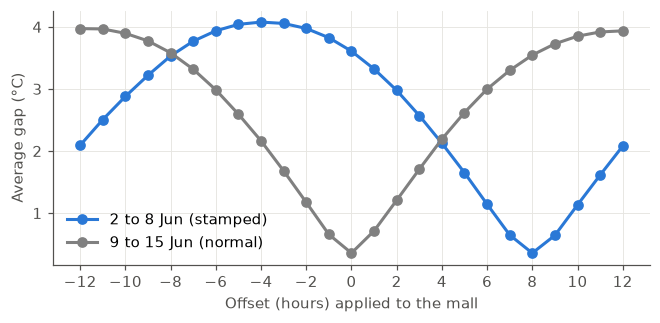

In [5]:
# One line per week: the lowest point is the offset where the office matches the mall best
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(scan.iloc[:, 0], marker="o", color=BUILDING_COLORS["B1"], label=scan.columns[0])
ax.plot(scan.iloc[:, 1], marker="o", color="grey", label=scan.columns[1])
ax.set_xticks(range(-12, 13, 2))
ax.set_xlabel("Offset (hours) applied to the mall")
ax.set_ylabel("Average gap (°C)")
ax.legend()
plt.show()

**How to read it:** each point is the average gap in °C between the office and the mall when I move the mall by that many hours. The lowest point is the right offset.

- Normal week (grey): the best offset is 0. The two clocks agree, as expected.
- Suspicious week (blue): the best offset is +8, and only +8. At +7 and +9 the gap is already bigger, and at -8 (office clock late) it is large. So the office clock was exactly 8 hours early, not late.

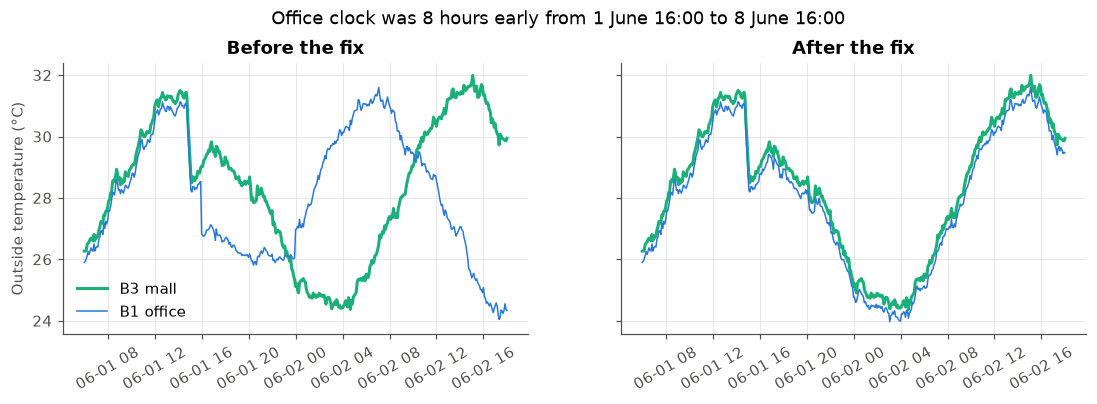

In [6]:
# The same story in a picture: office vs mall outside temperature at the start of the block
window = slice("2025-06-01 06:00", "2025-06-02 18:00")
fixed = add_building(fix_clock_shift(train))  # the fix, explained below
office_fixed = fixed[fixed["building"] == "B1"].groupby("timestamp")["oat_c"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for ax, office_series, title in [
    (axes[0], office, "Before the fix"),
    (axes[1], office_fixed, "After the fix"),
]:
    ax.plot(mall.loc[window], color=BUILDING_COLORS["B3"], label="B3 mall")
    ax.plot(office_series.loc[window], color=BUILDING_COLORS["B1"], label="B1 office", lw=1)
    ax.set_title(title)
    ax.tick_params(axis="x", labelrotation=30)
axes[0].set_ylabel("Outside temperature (°C)")
axes[0].legend()
fig.suptitle("Office clock was 8 hours early from 1 June 16:00 to 8 June 16:00", y=1.03)
save_fig(fig, "02_clock_shift")
plt.show()

**How to read the chart:** both lines measure the same outside air, so they should lie on top of each other. On the left, they split at 1 June 16:00. Until midnight the office line (blue) is the average of the two copies of each stamp, so it sits between the real values. After midnight it runs 8 hours ahead: its daily peak comes around 06:00 instead of 14:00. On the right, after the fix, both lines follow each other again. The sudden drop at 15:00 in both buildings is probably an afternoon thunderstorm.

### Which of the duplicate rows is the real one?

The block starts at 1 June 16:00 (stamped). Real 1 June evening rows and early-clock 2 June night rows land on the same stamps, so each stamp from 16:00 to 23:55 exists twice. These are the 96 "duplicates" per office machine from notebook 01. I need to know which copy to move.

In [7]:
# Number each copy of a repeated stamp in file order: 0 = first copy, 1 = second copy
office_rows = train[train["building"] == "B1"].copy()
dups = office_rows[office_rows.duplicated(["ahu_id", "timestamp"], keep=False)].copy()
dups["copy"] = dups.groupby(["ahu_id", "timestamp"]).cumcount()

# For each copy: gap to the mall at the same time, gap to the mall 8 hours later, and fan on
dups["same_time"] = (dups["oat_c"] - mall.reindex(dups["timestamp"]).values).abs()
dups["mall_8h_later"] = (
    dups["oat_c"] - mall.reindex(dups["timestamp"] + pd.Timedelta("8h")).values
).abs()
dups.groupby("copy").agg(
    rows=("ahu_id", "size"),
    same_time=("same_time", "mean"),
    mall_8h_later=("mall_8h_later", "mean"),
    fan_on=("fan_status", "mean"),
).round(2).assign(fan_on=lambda t: t["fan_on"].map("{:.1%}".format))

,rows,same_time,mall_8h_later,fan_on
copy,,,,
0,1523,0.35,2.89,13.0%
1,1523,3.44,0.36,24.0%


**How to read it:** the table has one row per copy. 16 machines × 96 stamps would give 1,536 pairs; I find 1,523 because 13 stamps have only one row (see below).

- Copy 0 matches the mall at the same time (0.35 °C). It is the real Sunday 1 June evening. Its fan is on in 12.5% of rows: exactly the 2 office machines out of 16 that run 24/7.
- Copy 1 matches the mall 8 hours later (0.36 °C). It is Monday 2 June from 00:00 to 08:00. More fans are on (23.5%) because the office starts in the early morning.

So the first copy in the file is the real one and the second copy is the one to move.

What about the 13 stamps with only one row? There is no pair, so file order tells me nothing. I check them against the mall too.

In [8]:
# Stamps between 1 June 16:00 and midnight with only one office row
overlap = office_rows[office_rows["timestamp"] < "2025-06-02"]
overlap = overlap[overlap["timestamp"] >= CLOCK_SHIFT_START]
single = overlap[overlap.groupby(["ahu_id", "timestamp"])["timestamp"].transform("size") == 1]

# Which clock does each one match better: the mall at the same time or 8 hours later?
gap_same = (single["oat_c"] - mall.reindex(single["timestamp"]).values).abs()
gap_8h = (single["oat_c"] - mall.reindex(single["timestamp"] + pd.Timedelta("8h")).values).abs()
matches = (gap_same < gap_8h).map({True: "real 1 June evening", False: "early-clock 2 June night"})
matches.value_counts()

oat_c
real 1 June evening         8
early-clock 2 June night    5
Name: count, dtype: int64

**How to read it:** 8 of the 13 single rows are real 1 June rows. The other 5 are early-clock rows whose real twin is missing. A simple rule (keep them, or move them) would put some of them at the wrong time. They are only 13 rows out of about 2 million, so I drop them. A missing slot is better than a row with the wrong time.

### The fix

`fix_clock_shift()` in `src/ahu_fdd/data.py` adds 8 hours to the office rows stamped from 1 June 16:00 to 8 June 16:00. In the first 8 hours of the block it moves only the second copy, and drops the stamps that have only one row. The block limits are in `config.py`. A unit test in `tests/unit/test_data.py` checks it on a tiny example.

In [9]:
# Block limits (wrong stamps) and offset, from config.py
print(f"Stamped from {CLOCK_SHIFT_START} to {CLOCK_SHIFT_END}, moved by {CLOCK_SHIFT_OFFSET}")

# Duplicates and missing slots per building, before and after the fix
before = coverage_by_building(coverage_per_ahu(train))
after = coverage_by_building(coverage_per_ahu(fixed))
pd.concat({"before": before, "after": after}, axis=1).loc[
    :, (slice(None), ["machines_with_duplicates", "duplicates_max", "missing_pct_avg"])
]

Stamped from 2025-06-01 16:00 to 2025-06-08 16:00, moved by 8h


before                                 \
         machines_with_duplicates duplicates_max missing_pct_avg   
building                                                           
B1                             16             96            0.49   
B2                              0              0            4.89   
B3                             12            288            0.30   

                            after                                 
         machines_with_duplicates duplicates_max missing_pct_avg  
building                                                          
B1                              0              0            0.31  
B2                              0              0            4.89  
B3                             12            288            0.30

**How to read it:** after the fix the office has no duplicates (16 machines → 0) and its missing slots drop from about 0.5% to 0.3%, the same as the mall. The 8-hour hole on 8 June is filled by the moved rows. The other buildings don't change. Apart from the 13 single rows, I move rows, I don't drop any.

In [10]:
# Final check: in the fixed data, does the office week look like a normal office week again?
fixed["hour"] = fixed["timestamp"].dt.hour
office_week = fixed[
    (fixed["building"] == "B1")
    & (fixed["timestamp"] >= "2025-06-02")
    & (fixed["timestamp"] < "2025-06-07")  # Monday to Friday
]
on_by_hour = office_week.groupby("hour")["fan_status"].mean()
on_by_hour.loc[[3, 6, 7, 9, 12, 18, 20, 22]].map("{:.0%}".format)

hour
3      13%
6      13%
7     100%
9     100%
12    100%
18    100%
20     13%
22     13%
Name: fan_status, dtype: str

**How to read it:** share of office rows with the fan on, by hour, from Monday 2 to Friday 6 June after the fix. At night only the two 24/7 machines run (about 13%). From 07:00 the office machines start, and in the evening they stop again. That is the normal office schedule from notebook 01.

**Obs:** the office data from 1 June 16:00 to 8 June 16:00 (stamped) was saved 8 hours early. The weather proves it: the office outside temperature matches the mall 8 hours later, and the first copy of each duplicate matches at the same time. This explains three findings of notebook 01 at once: the night running, the 96 duplicates on 1 June and the 8-hour hole on 8 June. No fault event of the office falls in that week, so the labels are not affected.

**Decision:** I apply `fix_clock_shift()` to the train data before anything else. Test data has no shift (no duplicates, normal hours), so I leave it as it is.

**Ask the operator:** Did the office BMS change its time settings in early June 2025, for example after an update?
Why it matters: if it happens again in live data, the model sees the office "running at night" and could raise false alarms. A simple check on the clock (weather vs a neighbour building) would catch it.

## 2. The mall repeated day: are the two copies the same?

In notebook 01 every mall (B3) machine had up to 288 duplicate rows, one full day. If the two copies of each row are the same, I can keep one and lose nothing. If they differ, I need to know which one is right.

**How:** I start from the data with the office fix, find the stamps that still appear twice, and compare the two copies column by column.

In [11]:
# Stamps that still appear twice after the office fix: which buildings and which days?
key = ["ahu_id", "timestamp"]
repeated = fixed[fixed.duplicated(key, keep=False)].copy()
repeated["day"] = repeated["timestamp"].dt.strftime("%a %d %b")
repeated.groupby(["building", "day"]).agg(machines=("ahu_id", "nunique"), rows=("ahu_id", "size"))

,,machines,rows
building,day,,
B3,Fri 14 Feb,12,6878


**How to read it:** only the mall is left, and only one day: Friday 14 February, in all 12 machines. 6,878 rows = 3,439 pairs. A full day would be 12 × 288 = 3,456 pairs; 17 stamps of that day have only one row (normal missing slots).

In [12]:
# Put the two copies of each stamp side by side: copy 0 = first in the file, copy 1 = second
repeated["copy"] = repeated.groupby(key).cumcount()
sensors = [c for c in train.columns if c not in ("ahu_id", "timestamp", "building")]
first = repeated[repeated["copy"] == 0].set_index(key)[sensors]
second = repeated[repeated["copy"] == 1].set_index(key)[sensors]

# Two values are "the same" if they are equal or both empty (NaN)
same = first.eq(second) | (first.isna() & second.isna())
print(f"Pairs identical in every column: {same.all(axis=1).mean():.1%}")

Pairs identical in every column: 97.9%


In [13]:
# For the columns where some pairs differ: how many, and is it a real disagreement?
differ = ~same
one_is_empty = differ & (first.isna() | second.isna())
summary = pd.DataFrame(
    {"pairs_that_differ": differ.sum(), "of_which_one_copy_is_empty": one_is_empty.sum()}
)
summary[summary["pairs_that_differ"] > 0]

,pairs_that_differ,of_which_one_copy_is_empty
fan_power_kw,16,16
sat_c,20,20
mat_c,15,15
rat_c,10,10
chw_valve_cmd_pct,12,12


**How to read it:** 97.9% of the pairs are exact copies. In the other 2.1% (72 pairs) one sensor value is empty (NaN) in one copy and filled in the other. For example, `sat_c` differs in 20 pairs, and in all 20 one of the two copies is empty. The two copies never give two different numbers.

**Obs:** 14 February was saved twice for every mall machine, with the same readings. The only difference is a few empty values, about the same rate (0.2%) as the nulls I see in all the train data. It looks like the same day was exported twice, each time losing a few different values.

**Decision:** I keep one row per stamp and fill an empty value in one copy with the value of the other copy (`merge_duplicates()` in `src/ahu_fdd/data.py`). No information is lost, and I even recover the 73 empty values of that day. I run it after `fix_clock_shift()`: before that fix, the office "duplicates" are two different hours and must not be merged.

**Ask the operator:** How was the mall data exported? Was it joined from several files?
Why it matters: an overlap between two exports would explain the repeated day. If the live pipeline joins files the same way, it needs the same check.

In [14]:
# Apply the merge and check: no duplicates left, rows removed = repeated pairs
clean = merge_duplicates(fixed)
print(f"Rows before: {len(train):,}  after: {len(clean):,}  removed: {len(train) - len(clean):,}")
coverage_by_building(coverage_per_ahu(add_building(clean)))[
    ["machines_with_duplicates", "duplicates_max", "missing_pct_avg"]
]

Rows before: 2,053,533  after: 2,050,081  removed: 3,452


,machines_with_duplicates,duplicates_max,missing_pct_avg
building,,,
B1,0,0,0.31
B2,0,0,4.89
B3,0,0,0.30


**How to read it:** 3,452 rows removed = 3,439 mall copies + the 13 ambiguous office rows of section 1. No building has duplicates now. The hospital still misses about 4.9% of its slots: that is the next section.

## 3. The hospital missing days: one long gap or many small ones?

In notebook 01 every hospital (B2) machine missed about 4.9% of its 5-minute slots, around 9 days. Many small gaps would mean a flaky sensor or network. One long gap at the same time in all machines would mean the BMS stopped saving.

**How:** `gap_blocks()` in `src/ahu_fdd/eda.py` joins consecutive missing slots into blocks. A block of 1 slot = 5 minutes missing.

In [15]:
# One row per block of missing slots, for every machine of the cleaned data
gaps = add_building(gap_blocks(clean))

# Per building: how many blocks, how long they usually are, and the longest one
gaps.groupby("building").agg(
    blocks=("slots", "size"),
    blocks_of_1_slot=("slots", lambda s: f"{(s == 1).mean():.1%}"),
    longest_minutes=("hours", lambda h: h.max() * 60),
)

,blocks,blocks_of_1_slot,longest_minutes
building,,,
B1,2559,99.9%,10.0
B2,1787,99.0%,12000.0
B3,1893,99.8%,10.0


**How to read it:** in the office and the mall, almost every block is a single 5-minute slot (99.8% or more), and the longest is 10 minutes. In the hospital, 99% of the blocks are single slots too, but the longest is 12,000 minutes (200 hours). Let's look at the long ones.

In [16]:
# Blocks of one hour or more, with the day names
long_gaps = gaps[gaps["hours"] >= 1].copy()
long_gaps["from"] = long_gaps["start"].dt.strftime("%a %d %b %H:%M")
long_gaps["to"] = long_gaps["end"].dt.strftime("%a %d %b %H:%M")
long_gaps.groupby(["building", "from", "to", "hours"]).agg(machines=("ahu_id", "nunique"))

,,,,machines
building,from,to,hours,
B2,Mon 10 Mar 06:00,Tue 18 Mar 13:55,200.0,12


**How to read it:** one line only. All 12 hospital machines miss exactly the same slots, from Monday 10 March 06:00 to Tuesday 18 March 13:55 (last missing slot). That is 200 hours, about 8.3 days.

In [17]:
# Does the long gap hit a labelled fault event? (an event is lost if its rows are missing)
labels = load_labels()
gap_start, gap_end = long_gaps["start"].min(), long_gaps["end"].max()
in_gap_machines = labels["ahu_id"].isin(long_gaps["ahu_id"])
overlaps = (labels["start"] <= gap_end) & (labels["end"] >= gap_start)
print(f"Hospital fault events that overlap the gap: {(in_gap_machines & overlaps).sum()}")

Hospital fault events that overlap the gap: 0


In [18]:
# Same check on the test data (no cleaning needed there): any long gap?
test_gaps = gap_blocks(load_sensors("test"))
print(f"Test: {len(test_gaps):,} blocks, longest {test_gaps['hours'].max() * 60:.0f} minutes")

Test: 2,242 blocks, longest 10 minutes


**Obs:** the hospital lost one block of 8.3 days, in all 12 machines at the same time. A broken sensor would hit one machine; this hits the whole building, so the BMS or its network stopped saving data. No hospital fault event falls in that gap, so no label is lost. (A mall event, B3-AHU-02, runs at the same dates, but the mall data is complete.) Apart from that, every building (train and test) only has short gaps of 5 or 10 minutes spread over the period. They are about 0.3% of the slots.

**Decision:**
- I don't fill the 8-day gap. There is no data to fill it from, and invented values would teach the model a fake "normal".
- I don't fill the short 5-10 minute gaps either, for now. When I build the features (rolling windows over time), I will use time-based windows, so a missing slot only means one value less in the window. If a model needs a value in every slot, I will decide then.

**Ask the operator:** Was the hospital BMS or its network down from 10 to 18 March 2025?
Why it matters: if outages like this happen in live data, the system must notice "no data" and not take it as "no fault". It should also not raise alarms just after the data comes back.

## 4. Can I trust each value?

Sections 1-3 were about rows: wrong time, repeated, missing. Now I look inside the rows: empty values, values that can't be true, and sensors that stop moving.

**How:** four quick checks, each one a question:
1. Which values are empty?
2. Are there values that are physically impossible?
3. Is any sensor frozen (the same value for hours)?
4. Do the three fan signals (status, speed, power) agree?

### 4.1 Which values are empty?

In [19]:
# Share of empty values (NaN) per building, only for columns that have some
sensor_cols = [c for c in train.columns if c not in ("ahu_id", "timestamp", "building")]
empty = clean.groupby("building")[sensor_cols].apply(lambda g: g.isna().mean()).T
empty[empty.max(axis=1) > 0].map("{:.1%}".format)

building,B1,B2,B3
fan_power_kw,0.2%,0.2%,0.2%
sat_c,0.2%,0.2%,0.2%
mat_c,0.2%,0.2%,0.2%
rat_c,0.2%,0.2%,0.2%
chw_valve_cmd_pct,0.2%,0.2%,0.2%
co2_ppm,0.0%,0.0%,100.0%
sa_flow_m3h,100.0%,0.0%,100.0%


**How to read it:** `co2_ppm` and `sa_flow_m3h` are 100% empty where the building has no such sensor. From the ID cards: the office has CO2, the hospital has CO2 and airflow, the mall has neither. That is expected. Five other columns have about 0.2% empty values in every building.

**Obs:** the 0.2% is spread evenly over buildings and sensors (fan power, three temperatures and the valve). It looks like random small losses when the data was saved. Test has no empty values apart from the sensors that don't exist.

**Decision:** I keep them as NaN. 0.2% is too little to matter, and the model I choose must accept NaN (or I fill them at feature time).

### 4.2 Are there values that can't be true?

**How:** the min and max of every sensor, and two checks with physics: fan power against the rated power of the fan (from the ID cards), and CO2 against the range of the sensor.

In [20]:
# Min and max of each sensor, after the row fixes of sections 1-3
clean[sensor_cols].agg(["min", "max"]).T.round(1)

,min,max
fan_status,0.000000,1.000000
fan_speed_pct,0.000000,100.000000
fan_power_kw,0.000000,12106.000000
supply_static_pa,0.000000,350.000000
supply_static_sp_pa,0.000000,320.000000
sat_c,6.900000,31.700001
sat_sp_c,12.500000,14.500000
mat_c,20.900000,31.900000
rat_c,20.900000,31.600000
zone_temp_sp_c,23.000000,25.000000


**How to read it:** most ranges make sense for a building in Singapore: outside air 20.6 to 33.7 °C, supply air from 6.9 °C (cooling hard) to 31.7 °C (fan off, air warms up), valve and fan speed 0 to 100%. Two values stand out: fan power up to 12,106 kW (a fan of these machines is rated at a few tens of kW) and CO2 from 0 to 5,000 ppm.

In [21]:
# Fan power as a share of the rated power of each fan (1.0 = running at full power)
meta = load_metadata()
rated = clean["ahu_id"].map(meta.set_index("ahu_id")["fan_rated_kw"])
power_share = clean["fan_power_kw"] / rated

# Machines that ever go above 1.5 times their rated power
over = clean[power_share > 1.5]
over.groupby("ahu_id").agg(
    rows=("timestamp", "size"),
    first=("timestamp", "min"),
    last=("timestamp", "max"),
)

,rows,first,last
ahu_id,,,
B3-AHU-04,6007,2025-04-01,2025-04-21 23:55:00


In [22]:
# B3-AHU-04: typical fan power per week, with the fan off and on
b3_04 = clean[clean["ahu_id"] == "B3-AHU-04"].set_index("timestamp")
weekly = b3_04.groupby("fan_status")["fan_power_kw"].resample("W-MON", label="left", closed="left")
weekly = weekly.median().unstack(0).rename(columns={0: "fan_off", 1: "fan_on"})
weekly.loc["2025-03-17":"2025-05-05"].round(2)

fan_status,fan_off,fan_on
timestamp,,
2025-03-17,0.04,5.840000
2025-03-24,0.04,6.290000
2025-03-31,40.00,5970.350098
2025-04-07,40.00,5964.500000
2025-04-14,40.00,7114.729980
2025-04-21,0.04,7.390000
2025-04-28,0.04,7.180000
2025-05-05,0.04,7.190000


**How to read it:** each row is a week starting that Monday. With the fan off, a fan uses 0.04 kW (the controller is still powered). For three weeks, from 1 to 21 April, B3-AHU-04 reads 40 instead of 0.04 with the fan off, and 6,000 to 7,000 instead of 6 to 7 with the fan on. Everything is 1,000 times bigger. (The week of 31 March already shows it because 1 April is its Tuesday.)

**Obs:** for three weeks this machine logged fan power in watts instead of kW. Before and after, and in test, it is fine. No fault event of this machine falls in those weeks.

**Decision:** I divide its fan power by 1,000 from 1 to 21 April (`fix_power_units()` in `src/ahu_fdd/data.py`, dates in `config.py`).

In [23]:
# CO2: how many readings are exactly at the sensor limits (0 or 5000 ppm), and where?
at_limit = clean[clean["co2_ppm"].isin([0, 5000])]
at_limit.groupby("ahu_id").agg(
    rows=("co2_ppm", "size"),
    at_0=("co2_ppm", lambda c: (c == 0).sum()),
    at_5000=("co2_ppm", lambda c: (c == 5000).sum()),
    first=("timestamp", "min"),
    last=("timestamp", "max"),
)

,rows,at_0,at_5000,first,last
ahu_id,,,,,
B2-AHU-03,781,663,118,2025-01-20 01:00:00,2025-02-27 22:55:00


**How to read it:** only one hospital machine, B2-AHU-03, has CO2 readings at exactly 0 or 5,000 ppm: 781 rows between 20 January and 27 February. Outside air has about 420 ppm and an occupied room rarely goes above 2,000 ppm, so 0 and 5,000 are not real. They are the limits of the sensor range. They come mixed with normal readings (about 7% of the rows in that period), so the sensor was glitching, not dead.

**Decision:** I set these readings to NaN (`blank_co2_limits()`). The other readings of that sensor look normal, so I keep them.

### 4.3 Is any sensor frozen?

A real temperature always moves a little, even with the fan off. If a sensor gives exactly the same value for hours, it is frozen (or the BMS stopped updating it).

**How:** `longest_runs()` in `src/ahu_fdd/eda.py` finds, for each machine and sensor, the longest stretch with exactly the same value. I check the five temperatures, in train and test.

In [24]:
# Longest flat stretch per sensor: the typical machine and the worst machine, in hours
test_raw = load_sensors("test")
runs = pd.concat(
    {
        "train": longest_runs(clean, list(FROZEN_SENSORS)),
        "test": longest_runs(test_raw, list(FROZEN_SENSORS)),
    },
    names=["split"],
).reset_index(level=0)
per_sensor = runs.groupby(["sensor", "split"])["hours"].agg(typical="median", worst="max")
per_sensor.unstack("split").round(1)

typical        worst       
split      test train   test  train
sensor                             
chwst_c     0.9   1.0    1.4    1.3
mat_c       0.5   0.6    0.7    0.7
oat_c       0.5   0.6    0.7    0.7
rat_c       0.8   0.8    1.1  526.7
sat_c       0.8   0.8  215.6    1.2

**How to read it:** for a typical machine, the longest flat stretch is about 1 hour or less, for every sensor. Two cases are far away from the rest: `rat_c` in train (527 hours, about 22 days) and `sat_c` in test (216 hours, 9 days).

In [25]:
# The two frozen sensors
runs[runs["hours"] > FROZEN_MIN_HOURS]

,split,ahu_id,sensor,start,end,hours,value
32,train,B1-AHU-07,rat_c,2025-05-05,2025-05-26 23:55:00,526.666667,23.4
115,test,B2-AHU-08,sat_c,2025-07-21,2025-07-29 23:55:00,215.583333,13.1


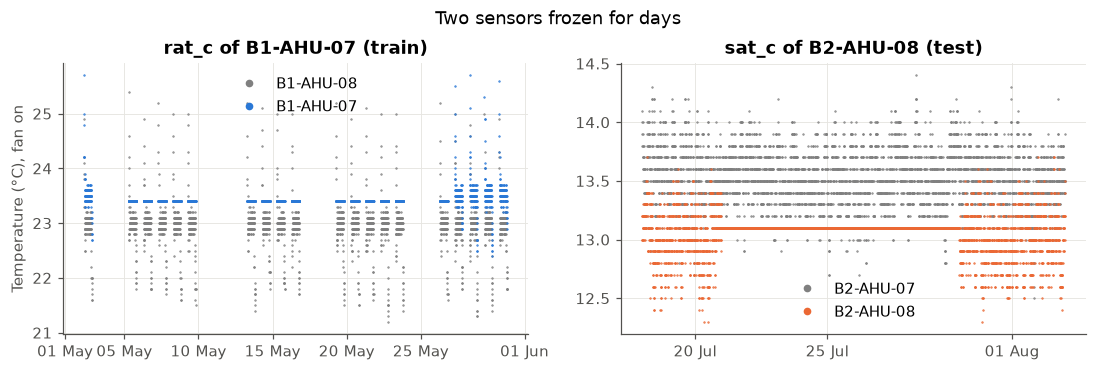

In [26]:
# Picture: each frozen sensor next to a healthy machine of the same building
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
cases = [
    (axes[0], clean, "rat_c", "B1-AHU-07", "B1-AHU-08", "2025-05-01", "2025-05-31", "B1"),
    (axes[1], test_raw, "sat_c", "B2-AHU-08", "B2-AHU-07", "2025-07-18", "2025-08-02", "B2"),
]
for ax, data, col, frozen_ahu, healthy_ahu, start, end, building in cases:
    for ahu_id, color in [(healthy_ahu, "grey"), (frozen_ahu, BUILDING_COLORS[building])]:
        one = data[(data["ahu_id"] == ahu_id) & (data["fan_status"] == 1)].set_index("timestamp")
        ax.plot(one.loc[start:end, col], ".", ms=1, color=color, label=ahu_id)
    ax.set_title(f"{col} of {frozen_ahu} ({'train' if data is clean else 'test'})")
    # Ticks on fixed days of the month, so labels never overlap at the end of a month
    ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 5, 10, 15, 20, 25]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.legend(markerscale=8)
axes[0].set_ylabel("Temperature (°C), fan on")
fig.suptitle("Two sensors frozen for days", y=1.03)
save_fig(fig, "02_frozen_sensors")
plt.show()

**How to read the chart:** grey dots are a healthy machine of the same building, coloured dots the frozen one (only rows with the fan on). The healthy sensor moves all the time. The frozen one is a flat line: `rat_c` of B1-AHU-07 at 23.4 °C from 5 to 26 May (train), and `sat_c` of B2-AHU-08 at 13.1 °C from 21 to 29 July (test). Both start at 00:00 and end at 23:55.

**Obs:**
- In both cases the machine keeps working normally. For example, in B2-AHU-08 the valve keeps moving with the load. So what froze is the saved value, not the machine.
- A frozen sensor is not one of the four faults. It is closest to the lying thermometer (`sat_sensor_bias`), but that fault gives a value that moves with an offset, not a flat line.
- The test case matters: the frozen `sat_c` sits at 13.1 °C, 0.1 °C above its setpoint, so the machine looks perfect on that sensor. Any feature built on `sat_c` would be wrong for 9 days.
- No labelled event of these machines falls in these days.

**Decision:** I set a temperature reading to NaN when it doesn't change at all for 6 hours or more (`blank_frozen()`). Normal sensors never stay flat for more than about 1.5 hours, so 6 hours leaves a wide margin. I run it on train and test, so the model never trusts a frozen value. In phase 2, I need a model that accepts NaN and doesn't raise alarms just because a sensor is missing.

**Ask the operator:** Do you know why these two sensors stopped updating (B1-AHU-07 return air in May, B2-AHU-08 supply air in July)?
Why it matters: a frozen sensor is a real problem for the technicians, but it's not one of the four faults. I would report it as a separate "sensor issue" alert, not as a fault.

### 4.4 Do the fan signals agree?

In [27]:
# With the fan off, speed and power should be at rest. With the fan on, they should not.
on = clean["fan_status"] == 1
fixed_power = clean_sensors(train)["fan_power_kw"]  # power with the watts fixed
checks = {
    "fan on, speed 0%": (on & (clean["fan_speed_pct"] == 0)).sum(),
    "fan off, speed above 0%": (~on & (clean["fan_speed_pct"] > 0)).sum(),
    "fan off, power above 0.1 kW": (~on & (fixed_power > 0.1)).sum(),
    "fan on, power 0.1 kW or less": (on & (fixed_power <= 0.1)).sum(),
    "fan off, static pressure above 20 Pa": (~on & (clean["supply_static_pa"] > 20)).sum(),
}
pd.Series(checks, name="rows")

fan on, speed 0%                        0
fan off, speed above 0%                 0
fan off, power above 0.1 kW             0
fan on, power 0.1 kW or less            0
fan off, static pressure above 20 Pa    0
Name: rows, dtype: int64

**How to read it:** zero rows in every check. When the fan is off, speed, power and pressure are at rest; when it is on, they are not. The fan status is reliable, which is good news: it decides which rows are scored.

### 4.5 All the cleaning in one step

`clean_sensors()` in `src/ahu_fdd/data.py` runs every fix in order: clock shift, repeated rows, watts, CO2 limits, frozen sensors. From now on, every notebook and the model start from its output.

In [28]:
# What the cleaning changes, in train and test
summary_rows = {}
for split, raw in [("train", train), ("test", test_raw)]:
    cleaned = clean_sensors(raw)
    summary_rows[split] = {
        "rows_before": len(raw),
        "rows_after": len(cleaned),
        "values_set_to_nan": int(cleaned[sensor_cols].isna().sum().sum())
        - int(merge_duplicates(fix_clock_shift(raw))[sensor_cols].isna().sum().sum()),
    }
pd.DataFrame(summary_rows)

,train,test
rows_before,2053533,711994
rows_after,2050081,711994
values_set_to_nan,7087,2587


**How to read it:** in train, 3,452 rows are removed (repeated mall day and 13 ambiguous office rows) and 7,087 values are set to NaN (781 CO2 glitches and 6,306 frozen `rat_c` readings; the other 14 were already empty). In test no row is removed and 2,587 values are set to NaN (the frozen `sat_c`).

## Summary

- **One office week was stamped 8 hours early** (1 June 16:00 to 8 June 16:00). I proved it with the weather: the best match with the mall is exactly +8 hours. I fixed it with `fix_clock_shift()`: the office duplicates and the hole on 8 June are gone, and only 13 ambiguous rows are dropped.
- **The mall saved 14 February twice.** The copies have the same readings; only a few empty values differ. I keep one row and fill the empty values from the other copy with `merge_duplicates()`.
- **The hospital lost 8.3 days (10 to 18 March) in all 12 machines at once**, very likely a BMS outage. No hospital fault event falls there. I leave it as a gap. All other gaps are 5-10 minutes, in train and test.
- **About 0.2% empty values** in five sensors, spread evenly. I keep them as NaN.
- **One machine logged fan power in watts for three weeks** (B3-AHU-04, 1 to 21 April). I divide by 1,000.
- **One CO2 sensor glitched** to exactly 0 or 5,000 ppm (B2-AHU-03, 781 rows). I set those to NaN.
- **Two temperature sensors froze for days**: `rat_c` of B1-AHU-07 in train (22 days) and `sat_c` of B2-AHU-08 in test (9 days). I set readings that stay flat for 6 hours or more to NaN. The test case is important for false alarms in phase 2.
- Fan status, speed and power always agree, so the fan status is a reliable filter for scored rows.
- `clean_sensors()` runs all the fixes in order. Every next notebook starts from it.